In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd 

import matplotlib.pyplot as plt
import seaborn as sns 
%matplotlib inline

from geopy.geocoders import Nominatim
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

import category_encoders as ce
from sklearn.feature_selection import chi2
from sklearn.feature_selection import f_classif

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestRegressor 
from sklearn import metrics 


In [2]:
# зафиксируем версию пакетов, чтобы эксперименты были воспроизводимы:
!pip freeze > requirements.txt

### 0. Предварительное знакомство с данными.

!!!!!
Поскольку на GitHub ограничен размер загружаемых файлов, ниже ссылка на яндекс диск, откуда при необходимости можно скачать необходимые файлы: 

hotels_train.csv

hotels_test.csv

submission.csv

https://disk.yandex.ru/d/6AvziLprDmf0XQ


In [ ]:
# Загружаем данные
DATA_DIR = 'Data/'
df_train = pd.read_csv(DATA_DIR+'hotels_train.csv') # датасет для обучения
df_test = pd.read_csv(DATA_DIR+'hotels_test.csv') # датасет для предсказания
sample_submission = pd.read_csv(DATA_DIR+'submission.csv') # самбмишн

In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 386803 entries, 0 to 386802
Data columns (total 17 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   hotel_address                               386803 non-null  object 
 1   additional_number_of_scoring                386803 non-null  int64  
 2   review_date                                 386803 non-null  object 
 3   average_score                               386803 non-null  float64
 4   hotel_name                                  386803 non-null  object 
 5   reviewer_nationality                        386803 non-null  object 
 6   negative_review                             386803 non-null  object 
 7   review_total_negative_word_counts           386803 non-null  int64  
 8   total_number_of_reviews                     386803 non-null  int64  
 9   positive_review                             386803 non-null  object 
 

In [5]:
df_train.head(2)

,hotel_address,additional_number_of_scoring,review_date,average_score,hotel_name,reviewer_nationality,negative_review,review_total_negative_word_counts,total_number_of_reviews,positive_review,review_total_positive_word_counts,total_number_of_reviews_reviewer_has_given,reviewer_score,tags,days_since_review,lat,lng
0,Stratton Street Mayfair Westminster Borough Lo...,581,2/19/2016,8.4,The May Fair Hotel,United Kingdom,Leaving,3,1994,Staff were amazing,4,7,10.0,"[' Leisure trip ', ' Couple ', ' Studio Suite ...",531 day,51.507894,-0.143671
1,130 134 Southampton Row Camden London WC1B 5AF...,299,1/12/2017,8.3,Mercure London Bloomsbury Hotel,United Kingdom,poor breakfast,3,1361,location,2,14,6.3,"[' Business trip ', ' Couple ', ' Standard Dou...",203 day,51.521009,-0.123097


In [6]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128935 entries, 0 to 128934
Data columns (total 16 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   hotel_address                               128935 non-null  object 
 1   additional_number_of_scoring                128935 non-null  int64  
 2   review_date                                 128935 non-null  object 
 3   average_score                               128935 non-null  float64
 4   hotel_name                                  128935 non-null  object 
 5   reviewer_nationality                        128935 non-null  object 
 6   negative_review                             128935 non-null  object 
 7   review_total_negative_word_counts           128935 non-null  int64  
 8   total_number_of_reviews                     128935 non-null  int64  
 9   positive_review                             128935 non-null  object 
 

In [7]:
df_test.head(2)

,hotel_address,additional_number_of_scoring,review_date,average_score,hotel_name,reviewer_nationality,negative_review,review_total_negative_word_counts,total_number_of_reviews,positive_review,review_total_positive_word_counts,total_number_of_reviews_reviewer_has_given,tags,days_since_review,lat,lng
0,Via Senigallia 6 20161 Milan Italy,904,7/21/2017,8.1,Hotel Da Vinci,United Kingdom,Would have appreciated a shop in the hotel th...,52,16670,Hotel was great clean friendly staff free bre...,62,1,"[' Leisure trip ', ' Couple ', ' Double Room '...",13 days,45.533137,9.171102
1,Arlandaweg 10 Westpoort 1043 EW Amsterdam Neth...,612,12/12/2016,8.6,Urban Lodge Hotel,Belgium,No tissue paper box was present at the room,10,5018,No Positive,0,7,"[' Leisure trip ', ' Group ', ' Triple Room ',...",234 day,52.385649,4.834443


In [8]:
sample_submission.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128935 entries, 0 to 128934
Data columns (total 2 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   reviewer_score  128935 non-null  int64
 1   id              128935 non-null  int64
dtypes: int64(2)
memory usage: 2.0 MB


In [9]:
sample_submission.head(2)

,reviewer_score,id
0,1,488440
1,10,274649


In [10]:
# объединяем трейн и тест в один датасет
df_train['sample'] = 1 # помечаем трейн
df_test['sample'] = 0 # помечаем тест
df_test['reviewer_score'] = 0 # в тесте у нас нет значения reviewer_score, поэтому пока его просто заполняем нулями

data = pd.concat([df_train, df_test], axis=0) # объединяем

data.info() # смотрим что получилось

<class 'pandas.core.frame.DataFrame'>
Index: 515738 entries, 0 to 128934
Data columns (total 18 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   hotel_address                               515738 non-null  object 
 1   additional_number_of_scoring                515738 non-null  int64  
 2   review_date                                 515738 non-null  object 
 3   average_score                               515738 non-null  float64
 4   hotel_name                                  515738 non-null  object 
 5   reviewer_nationality                        515738 non-null  object 
 6   negative_review                             515738 non-null  object 
 7   review_total_negative_word_counts           515738 non-null  int64  
 8   total_number_of_reviews                     515738 non-null  int64  
 9   positive_review                             515738 non-null  object 
 10  r

### 1. Заполнение пропущенных значений в данных.

In [11]:
geolocator = Nominatim(user_agent="NVL")

data[['lat','lng']] = data[['lat','lng']].fillna(0) # заполняем нулями пропущенные значения
mask = ((data['lat'] == 0) | (data['lng'] == 0))
hotel_none = data[mask] # выделяем отсутствующие строки в данных

In [12]:
# создаем список отелей и их адресов, где отсутствуют координаты
hotel_list = hotel_none.hotel_name.value_counts().index.to_list()
hotel_adr = hotel_none.hotel_address.value_counts().index.to_list()

hotel_list[:3]

['Fleming s Selection Hotel Wien City', 'Hotel City Central', 'Hotel Atlanta']

In [13]:
hotel_adr[:3]

['Josefst dter Stra e 10 12 08 Josefstadt 1080 Vienna Austria',
 'Taborstra e 8 A 02 Leopoldstadt 1020 Vienna Austria',
 'W hringer Stra e 33 35 09 Alsergrund 1090 Vienna Austria']

In [14]:
list(zip(hotel_list, hotel_adr))[:3]

[('Fleming s Selection Hotel Wien City',
  'Josefst dter Stra e 10 12 08 Josefstadt 1080 Vienna Austria'),
 ('Hotel City Central', 'Taborstra e 8 A 02 Leopoldstadt 1020 Vienna Austria'),
 ('Hotel Atlanta', 'W hringer Stra e 33 35 09 Alsergrund 1090 Vienna Austria')]

In [15]:
# заполеяем пропуски в координатах
for h, a in zip(hotel_list, hotel_adr):
    
    a = a.split(' ')[-4:]
    a = a[0]+' '+a[1]+' '+a[2]+' '+a[3]  
    
    place = geolocator.geocode(a, exactly_one=True, language='en')
   
    data.loc[data['hotel_name'].eq(h) & data['lat'].eq(0), 'lat'] = place.latitude
    data.loc[data['hotel_name'].eq(h) & data['lng'].eq(0), 'lng'] = place.longitude

In [16]:
data.info() # смотрим результат

<class 'pandas.core.frame.DataFrame'>
Index: 515738 entries, 0 to 128934
Data columns (total 18 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   hotel_address                               515738 non-null  object 
 1   additional_number_of_scoring                515738 non-null  int64  
 2   review_date                                 515738 non-null  object 
 3   average_score                               515738 non-null  float64
 4   hotel_name                                  515738 non-null  object 
 5   reviewer_nationality                        515738 non-null  object 
 6   negative_review                             515738 non-null  object 
 7   review_total_negative_word_counts           515738 non-null  int64  
 8   total_number_of_reviews                     515738 non-null  int64  
 9   positive_review                             515738 non-null  object 
 10  r

In [17]:
# проверяем, чем заполнились нулевые значения координат на примере одного из отелей
data[data['hotel_name'] == 'Fleming s Selection Hotel Wien City'][['lat', 'lng']].iloc[0]

lat    48.210882
lng    16.347369
Name: 724, dtype: float64

### 2. Создание новых признаков.

In [18]:
# создадим новый признак "hotel_city" (город отеля)
data['hotel_city'] = data['hotel_address'].apply(lambda x: x.split()[-5] if 'United Kingdom' in x else x.split()[-2])
# посмотрим, какие значения получились в этом признаке
data['hotel_city'].value_counts()

hotel_city
London       262301
Barcelona     60149
Paris         59928
Amsterdam     57214
Vienna        38939
Milan         37207
Name: count, dtype: int64

In [19]:
# после создания признака "hotel_city", признаки "hotel_address" и "hotel_name" можно удалить
data.drop('hotel_address', axis=1, inplace=True)
data.drop('hotel_name', axis=1, inplace=True)

In [20]:
# создадим новые признаки из признака "review_date" (даты оставления отзыва), но сначала переведем его в формат datetime
data['review_date'] = pd.to_datetime(data['review_date'])

In [21]:
# создадим признак выходных "is_weekend" и сезона "review_quarter"
data['is_weekend'] = data['review_date'].dt.day_of_week >= 5
data['is_weekend'] = data['is_weekend'].astype(int) # преобразуем из True/False в тип int
data['review_quarter'] = data['review_date'].dt.quarter

In [22]:
# удалим из датасета ненужный теперь признак "review_date"
data.drop('review_date', axis=1, inplace=True)

In [23]:
# посморим на признак "tags"
data['tags'].head(5)

0    [' Leisure trip ', ' Couple ', ' Studio Suite ...
1    [' Business trip ', ' Couple ', ' Standard Dou...
2    [' Leisure trip ', ' Solo traveler ', ' Modern...
3    [' Leisure trip ', ' Solo traveler ', ' Standa...
4    [' Business trip ', ' Couple ', ' Standard Dou...
Name: tags, dtype: object

In [24]:
data['tags'].describe()

count                                                515738
unique                                                55242
top       [' Leisure trip ', ' Couple ', ' Double Room '...
freq                                                   5101
Name: tags, dtype: object

In [25]:
# извлечем информацию об типе поездки(бизнес, отдых) и заселение в отель парой(семьей) или одному

def leisure_or_business_trip(col):
    col = list(map(lambda x: x.strip(), col[3:-3].split("', '")))
    if "Leisure" in col[0]:
        return 1
    elif "Business" in col[0]:
        return 0
    return 0

def solo_or_couple(col):
    couple_words = ['couple', 'group', 'in' ,'family', 'with', 'children', 'other', 'older']
    col = list(map(lambda x: x.strip(), col[3:-3].split("', '")))
    def checker(col):
        for word in col:
            if word.lower() in couple_words:
                return 1
            else: return 0
        
    try: # на случай если в тагах всего 1 таг, тогда возьмем первый
        return checker(col[1].split())
    except IndexError: 
        return checker(col)
    
# создадим два новых признака
    
data['lazy_or_business_trip'] = data['tags'].apply(leisure_or_business_trip)
data['couple_or_solo'] = data['tags'].apply(solo_or_couple)

In [26]:
# удалим из датасета ненужный теперь признак "tags"
data.drop('tags', axis=1, inplace=True)

In [27]:
# национальность клиента, этот признак позже закодируем при помощи BinaryEncoder
display(data['reviewer_nationality'].value_counts())

reviewer_nationality
United Kingdom               245246
United States of America      35437
Australia                     21686
Ireland                       14827
United Arab Emirates          10235
                              ...  
Guinea                            1
Tuvalu                            1
Comoros                           1
Anguilla                          1
Cape Verde                        1
Name: count, Length: 227, dtype: int64

In [28]:
# признак "days_since_review" числовой, уберем лишние "day/days" после количества дней
data['days_since_review'] = data['days_since_review'].apply(lambda x: int(x.split()[0]))

In [29]:
# Создадим новые признаки из признаков "negative_review" и "positive_review" с помощью анализатора текстовых отзывов
nltk.downloader.download('vader_lexicon')
sent_analyzer = SentimentIntensityAnalyzer()

data['neg_scores'] = data['negative_review'].apply(sent_analyzer.polarity_scores)
data['pos_scores'] = data['positive_review'].apply(sent_analyzer.polarity_scores)

data['n_review_sentiments_neg'] = data['neg_scores'].apply(lambda x: x['neg'])
data['n_review_sentiments_neu'] = data['neg_scores'].apply(lambda x: x['neu'])
data['n_review_sentiments_pos'] = data['neg_scores'].apply(lambda x: x['pos'])
data['n_review_sentiments_compound'] = data['neg_scores'].apply(lambda x: x['compound'])

data['p_review_sentiments_neg'] = data['pos_scores'].apply(lambda x: x['neg'])
data['p_review_sentiments_neu'] = data['pos_scores'].apply(lambda x: x['neu'])
data['p_review_sentiments_pos'] = data['pos_scores'].apply(lambda x: x['pos'])
data['p_review_sentiments_compound'] = data['pos_scores'].apply(lambda x: x['compound'])

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Tatiana\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [30]:
# удалим из датасета ненужные теперь признаки "negative_review", "positive_review" и временно созданные "neg_scores", "pos_scores"
data.drop(['negative_review', 'positive_review', 'neg_scores', 'pos_scores'], axis=1, inplace=True)

### 3. Кодирование категориальных признаков.

In [31]:
# Закодируем номинальный категориальный признак "hotel_city" с помощью OneHotEncoder
encoder = ce.OneHotEncoder()
data_bin = encoder.fit_transform(data['hotel_city'])
data.drop('hotel_city', axis=1, inplace=True)
data = pd.concat([data, data_bin], axis=1)
#data_bin

In [32]:
# Закодируем номинальный категориальный признак "review_quarter" с помощью OneHotEncoder
encoder = ce.OneHotEncoder()
data_bin = encoder.fit_transform(data['review_quarter'].astype(object))
data.drop('review_quarter', axis=1, inplace=True)
data = pd.concat([data, data_bin], axis=1)
#data_bin

In [33]:
# Закодируем номинальный категориальный признак "reviewer_nationality" с помощью BinaryEncoder
encoder = ce.BinaryEncoder()
data_bin = encoder.fit_transform(data['reviewer_nationality'])
data.drop('reviewer_nationality', axis=1, inplace=True)
data = pd.concat([data, data_bin], axis=1)
#data_bin

### 4. Отбор признаков.

In [34]:
# посмотрим на размер получившегося датасета, у нас получилось 38 признаков + целевой признак и признак-указатель train/test
data.shape

(515738, 40)

In [35]:
# выведем список всех признаков
columns_list = data.columns.tolist()
print(columns_list)

['additional_number_of_scoring', 'average_score', 'review_total_negative_word_counts', 'total_number_of_reviews', 'review_total_positive_word_counts', 'total_number_of_reviews_reviewer_has_given', 'reviewer_score', 'days_since_review', 'lat', 'lng', 'sample', 'is_weekend', 'lazy_or_business_trip', 'couple_or_solo', 'n_review_sentiments_neg', 'n_review_sentiments_neu', 'n_review_sentiments_pos', 'n_review_sentiments_compound', 'p_review_sentiments_neg', 'p_review_sentiments_neu', 'p_review_sentiments_pos', 'p_review_sentiments_compound', 'hotel_city_1', 'hotel_city_2', 'hotel_city_3', 'hotel_city_4', 'hotel_city_5', 'hotel_city_6', 'review_quarter_1', 'review_quarter_2', 'review_quarter_3', 'review_quarter_4', 'reviewer_nationality_0', 'reviewer_nationality_1', 'reviewer_nationality_2', 'reviewer_nationality_3', 'reviewer_nationality_4', 'reviewer_nationality_5', 'reviewer_nationality_6', 'reviewer_nationality_7']


In [36]:
# распределим признаки по двум спискам - числовому и категориальному
num_cols = ['additional_number_of_scoring', 'average_score', 'review_total_negative_word_counts', 'total_number_of_reviews', 'review_total_positive_word_counts', 'total_number_of_reviews_reviewer_has_given', 'days_since_review', 
            'n_review_sentiments_neg', 'n_review_sentiments_neu', 'n_review_sentiments_pos', 'n_review_sentiments_compound', 'p_review_sentiments_neg', 'p_review_sentiments_neu', 'p_review_sentiments_pos', 'p_review_sentiments_compound']
cat_cols = ['lat', 'lng', 'is_weekend', 'lazy_or_business_trip', 'couple_or_solo', 'hotel_city_1', 'hotel_city_2', 'hotel_city_3', 'hotel_city_4', 'hotel_city_5', 'hotel_city_6', 'review_quarter_1', 'review_quarter_2', 'review_quarter_3', 
            'review_quarter_4', 'reviewer_nationality_0', 'reviewer_nationality_1', 'reviewer_nationality_2', 'reviewer_nationality_3', 'reviewer_nationality_4', 'reviewer_nationality_5', 'reviewer_nationality_6', 'reviewer_nationality_7'] 

#### 4.1 Категориальные признаки

In [37]:
# Оценим влияние категориальных признаков на целевую переменную с помощью теста хи-квадрат
target = data.query('sample == 1')['reviewer_score'].astype('int')

data_cat = data.query('sample == 1')[cat_cols]

data_cat['lng'] = data_cat['lng'] + 0.4  # здесь убираем отрицательные значения, иначе не работает хи-квадрат
print(target.shape, data_cat.shape)


(386803,) (386803, 23)


In [38]:
# смотрим на значения категориальных переменных
data_cat.describe()

,lat,lng,is_weekend,lazy_or_business_trip,couple_or_solo,hotel_city_1,hotel_city_2,hotel_city_3,hotel_city_4,hotel_city_5,...,review_quarter_3,review_quarter_4,reviewer_nationality_0,reviewer_nationality_1,reviewer_nationality_2,reviewer_nationality_3,reviewer_nationality_4,reviewer_nationality_5,reviewer_nationality_6,reviewer_nationality_7
count,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,...,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000,386803.000000
mean,49.433422,3.292427,0.263594,0.808598,0.763482,0.508719,0.115899,0.111183,0.072086,0.075434,...,0.276239,0.256262,0.003087,0.049079,0.185467,0.195596,0.262736,0.323322,0.184290,0.706895
std,3.460964,4.666337,0.440582,0.393405,0.424945,0.499925,0.320104,0.314359,0.258630,0.264090,...,0.447137,0.436569,0.055474,0.216034,0.388676,0.396659,0.440121,0.467745,0.387721,0.455187
min,41.328376,0.030242,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.214066,0.256628,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,51.499981,0.419886,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,51.516288,5.241163,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000
max,52.400181,16.858013,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


<Axes: >

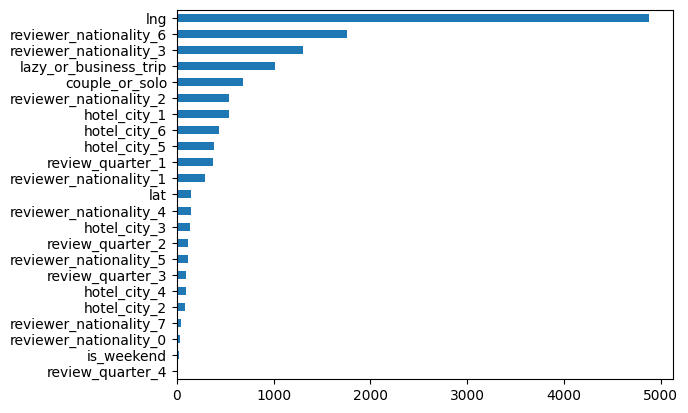

In [39]:
# проводим тест и смотрим результат
imp_cat = pd.Series(chi2(data_cat, target)[0], index=cat_cols)
imp_cat.sort_values(inplace = True)
imp_cat.plot(kind = 'barh')

<Axes: >

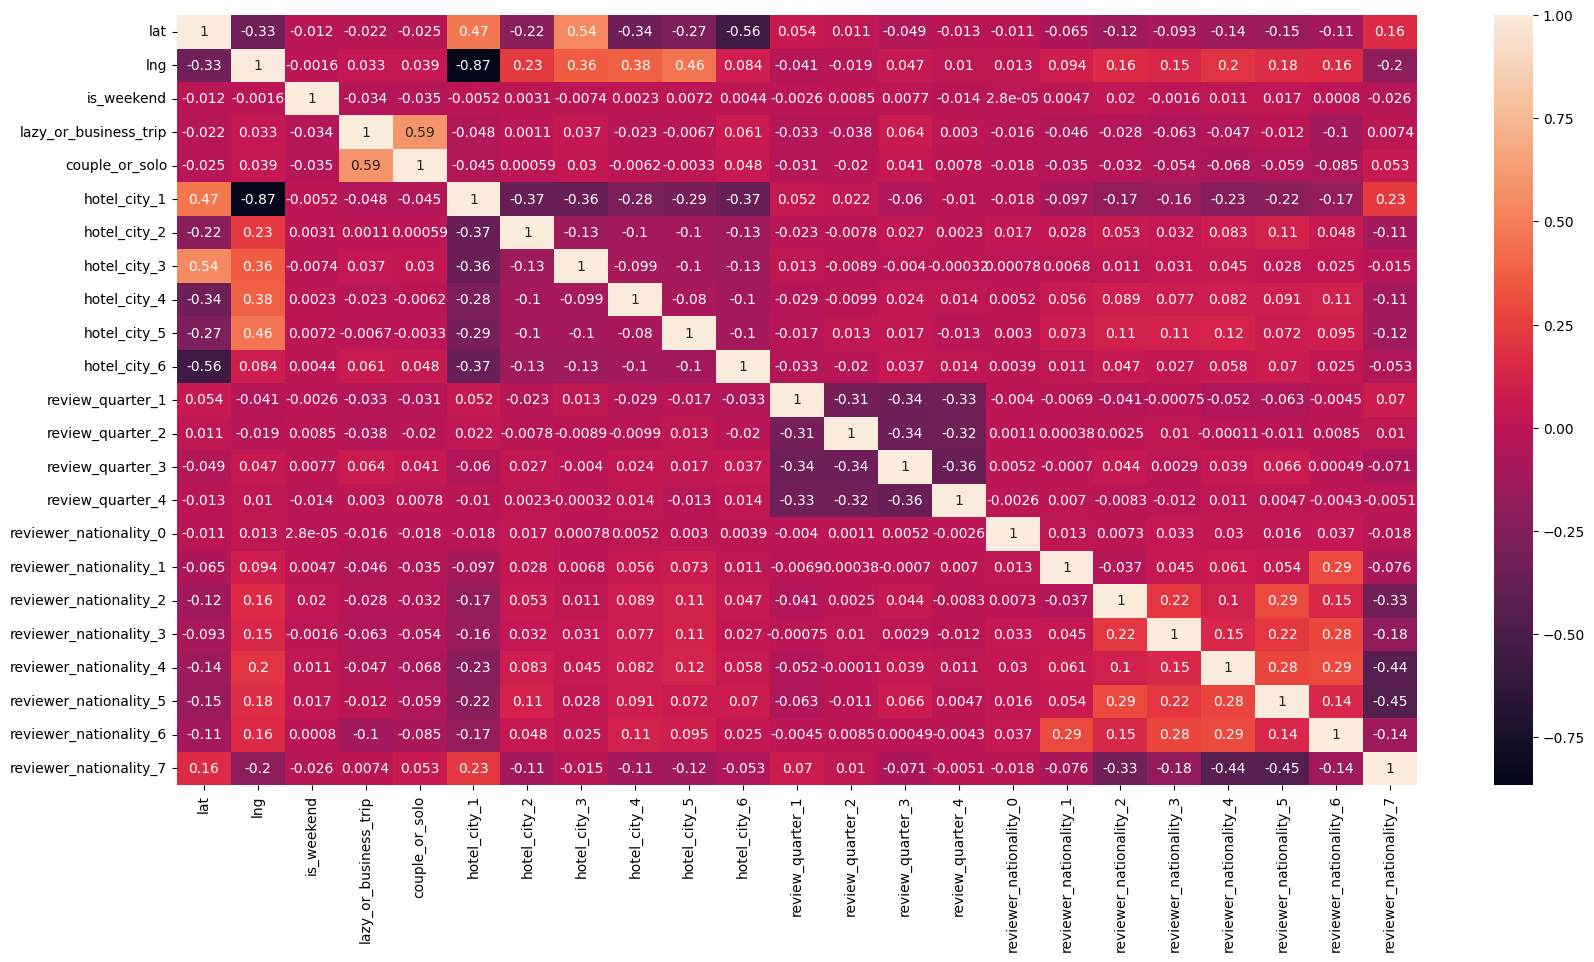

In [40]:
# проверим на мультиколлинеарность (метод Спирмена)
ax = plt.figure(figsize=(20,10))
sns.heatmap(data_cat.corr(method='spearman'), annot=True)

** Выводы по графикам и таблице корреляции категориальных признаков. **
1. Есть некоторая мультиколлинеарность у признаков "lng" и "hotel_city_1". Это можно объяснить прямой связью координат отеля и городом, где находится отель. Решил оставить оба признака.
2. Исходя из результатов статистического теста, такие признаки, как, например, "is_weekend" и "review_quarter_4" оказывают слабое влияние на целевую переменную. Поскольку количество признаков в получившемся датасете не слишком большое, решил оставить все признаки. Мы сможем сравнить важность признаков, полученную во время статистческого теста и после построения предсказательной модели RandomForestRegressor.

#### 4.2 Числовые признаки.

In [41]:
# выделим числовые признаки и проверим их количество
data_num = data.query('sample == 1')[num_cols]
print(data_num.shape)

(386803, 15)


<Axes: >

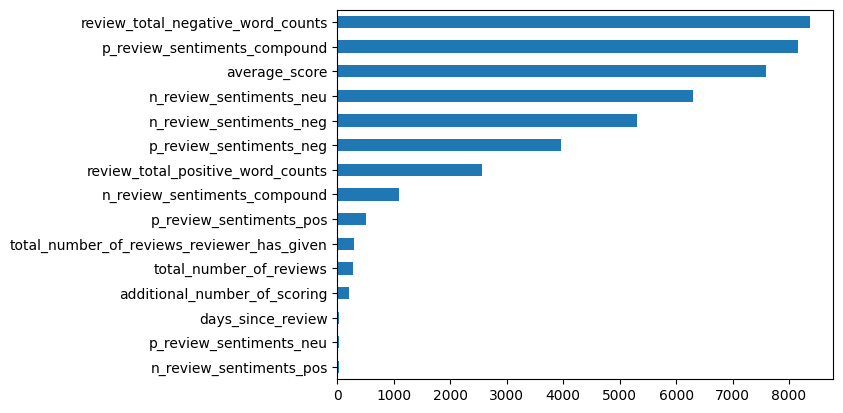

In [42]:
# оценим влияние числовых признаков на целевую переменную с помощью теста anova
imp_num = pd.Series(f_classif(data_num, target)[0], index = num_cols)
imp_num.sort_values(inplace = True)
imp_num.plot(kind = 'barh')

<Axes: >

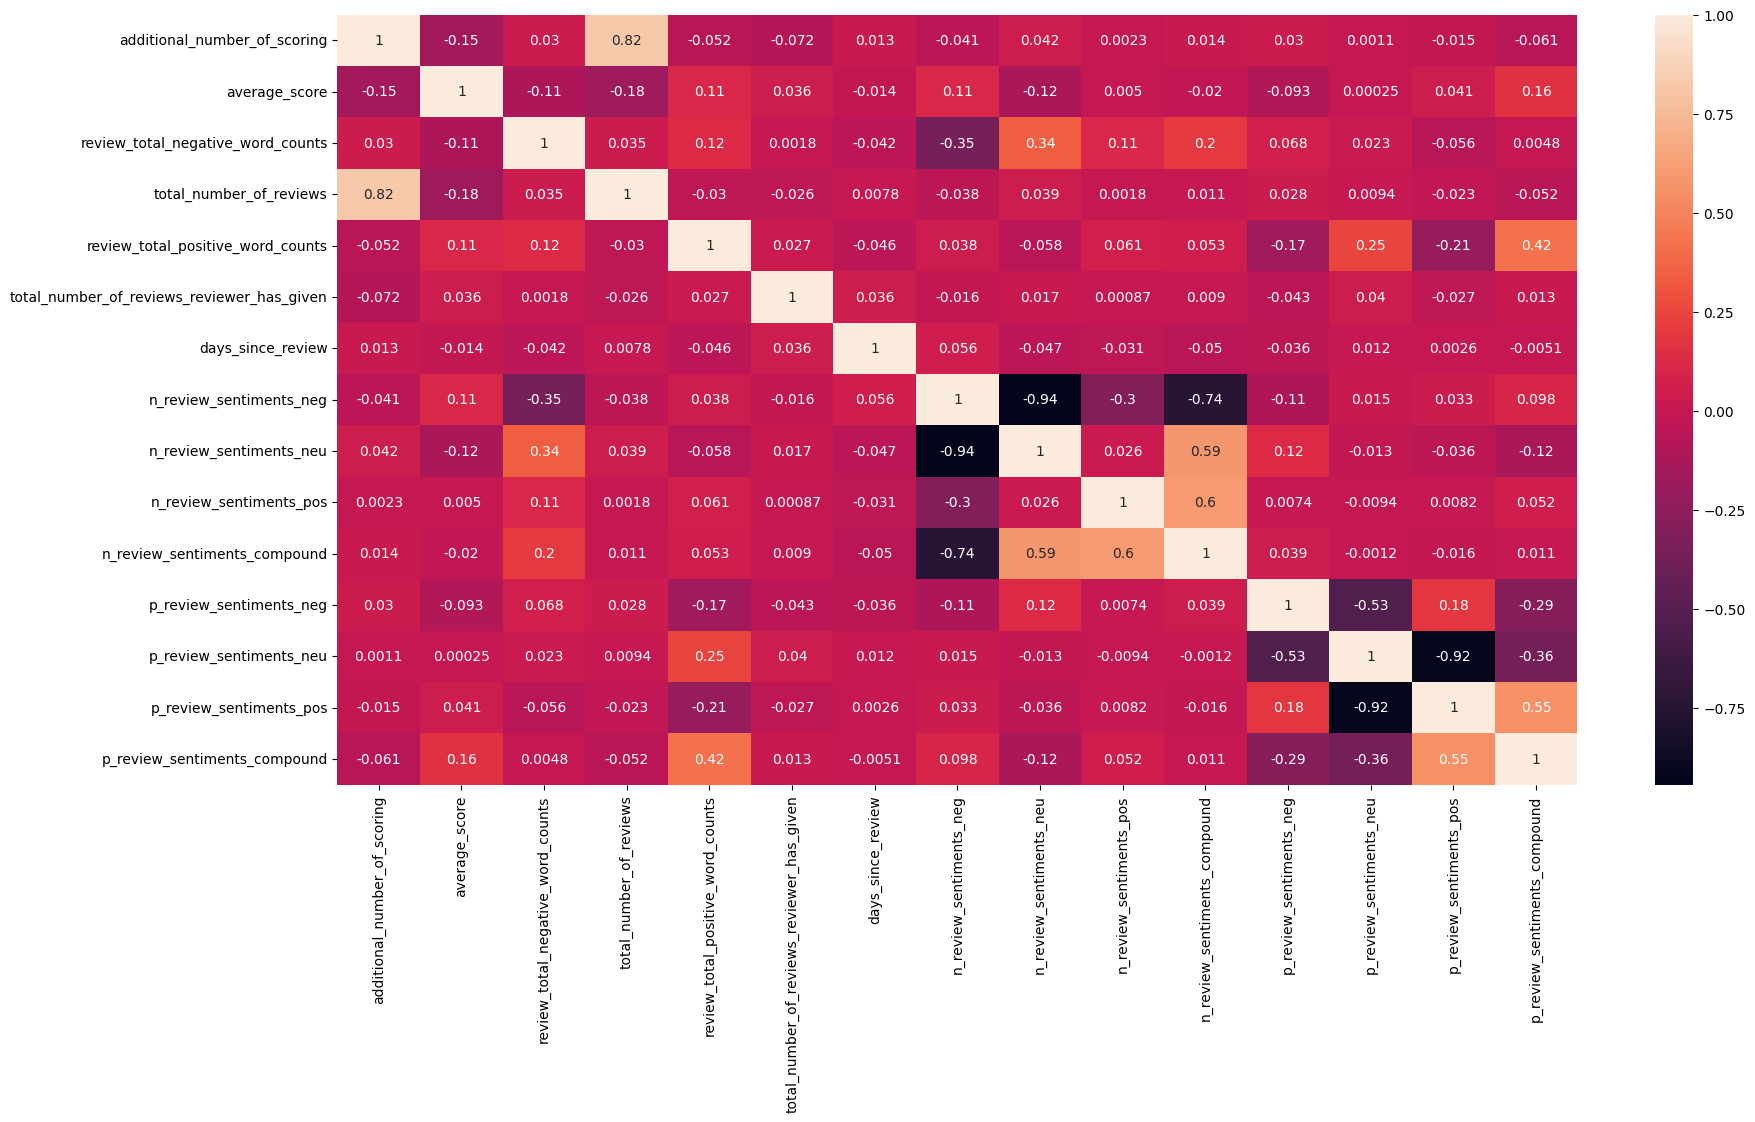

In [43]:
# проверим на мультиколлинеарность (метод Пирсона)
ax = plt.figure(figsize=(20,10))
sns.heatmap(data_num.corr(method='pearson'), annot=True)

Text(0.5, 0.98, 'распределения числовых признаков:')

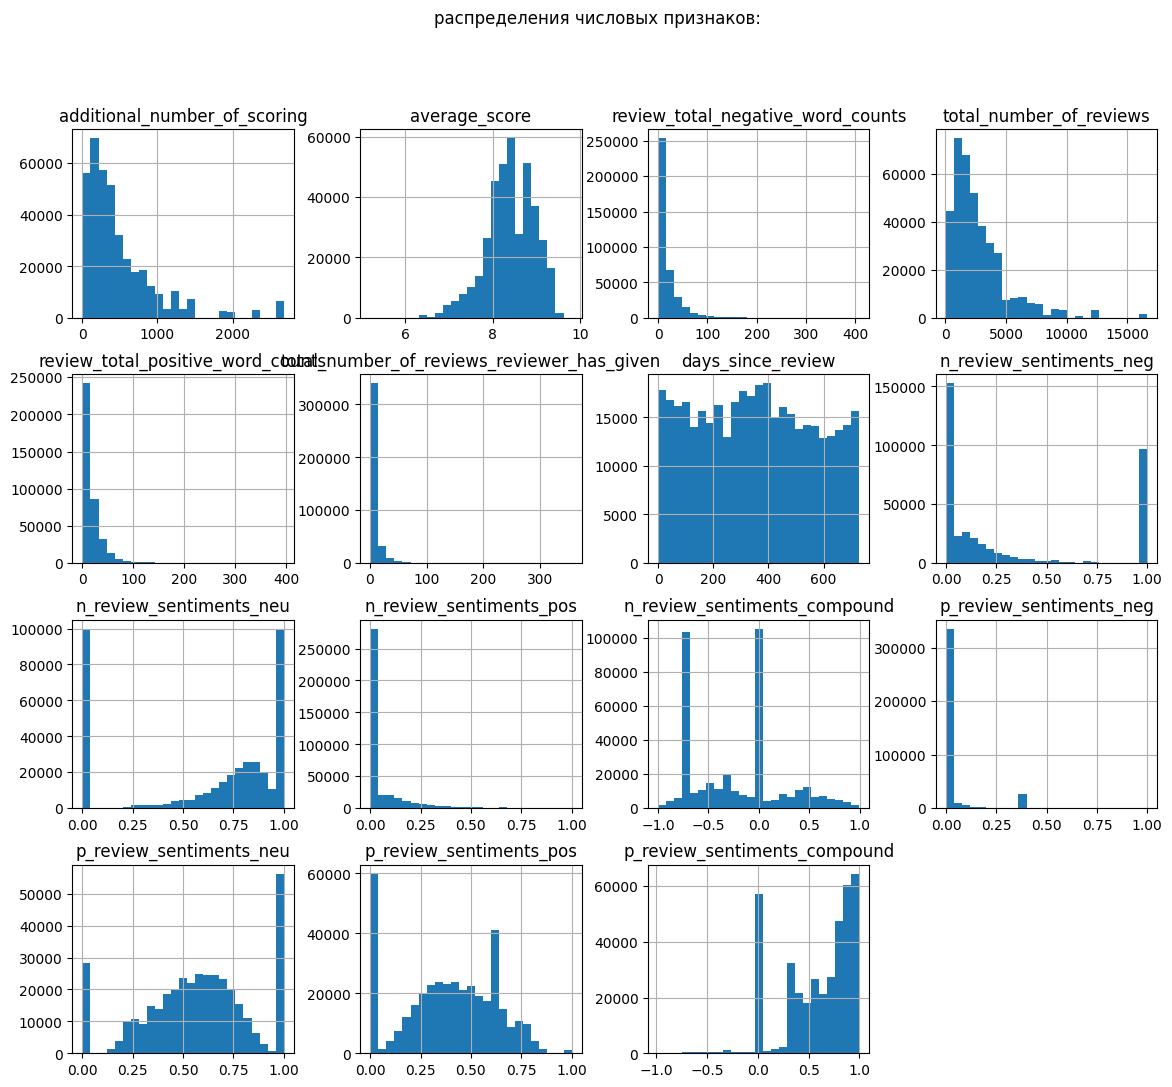

In [44]:
# Посмотрим на графики распределения числовых признаков
data_num.hist(bins=25, figsize=(14,12), layout=(4,4))
plt.suptitle('распределения числовых признаков:')

** Выводы по графикам и таблице корреляции числовых признаков. **
1. У числовых признаков также имеется мультиколлинеарность между некоторыми признаками, например "additional_number_of_scoring" и "total_number_of_reviews", что видно также и по графикам распределения. Решил оставить все признаки.
2. Также по результатам статистического теста можно оценить степень влияния признаков на целевую переменную. Решил оставить признаки со слабым влиянием по той же причине  - проверить их важность после построения предсказательной модели.

### 5. Модель RandomForestRegressor и оценка результата.

Поскольку такая предсказательная модель, как RandomForestRegressor, допускает обработку немасштабированных данных, решил опустить действия по нормированию или стандартизации числовых признаков, так как эти действия не окажут существенного влияния на конечный результат. В общем случае необходимо применить к данным масштабирование основе MinMaxScaler или стандартизацию на основе StandardScaler.

In [45]:
# Ввыделим тренировочную и тестовую часть из нашего датасета, используя маркер-признак "sample"
train_data = data.query('sample == 1').drop(['sample'], axis=1)
test_data = data.query('sample == 0').drop(['sample'], axis=1)

y = train_data.reviewer_score.values  # наш таргет
X = train_data.drop(['reviewer_score'], axis=1)

In [46]:
# Разобьем данные на тренировочную и тестовую части
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [47]:
# проверяем размерность
test_data.shape, train_data.shape, X.shape, X_train.shape, X_test.shape

((128935, 39), (386803, 39), (386803, 38), (309442, 38), (77361, 38))

In [48]:
# Создаём модель RandomForestRegressor
model = RandomForestRegressor(n_estimators=100, verbose=1, n_jobs=-1, random_state=42)

In [49]:
# Обучаем модель на тестовом наборе данных
model.fit(X_train, y_train)

# Предсказанные значения записываем в переменную y_pred
y_pred = model.predict(X_test)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  4.7min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.6s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:    1.7s finished


In [50]:
#  Метрика Mean Absolute Percentage Error (MAPE) 
print('MAPE:', metrics.mean_absolute_percentage_error(y_test, y_pred))

MAPE: 0.1253923354839803


<Axes: >

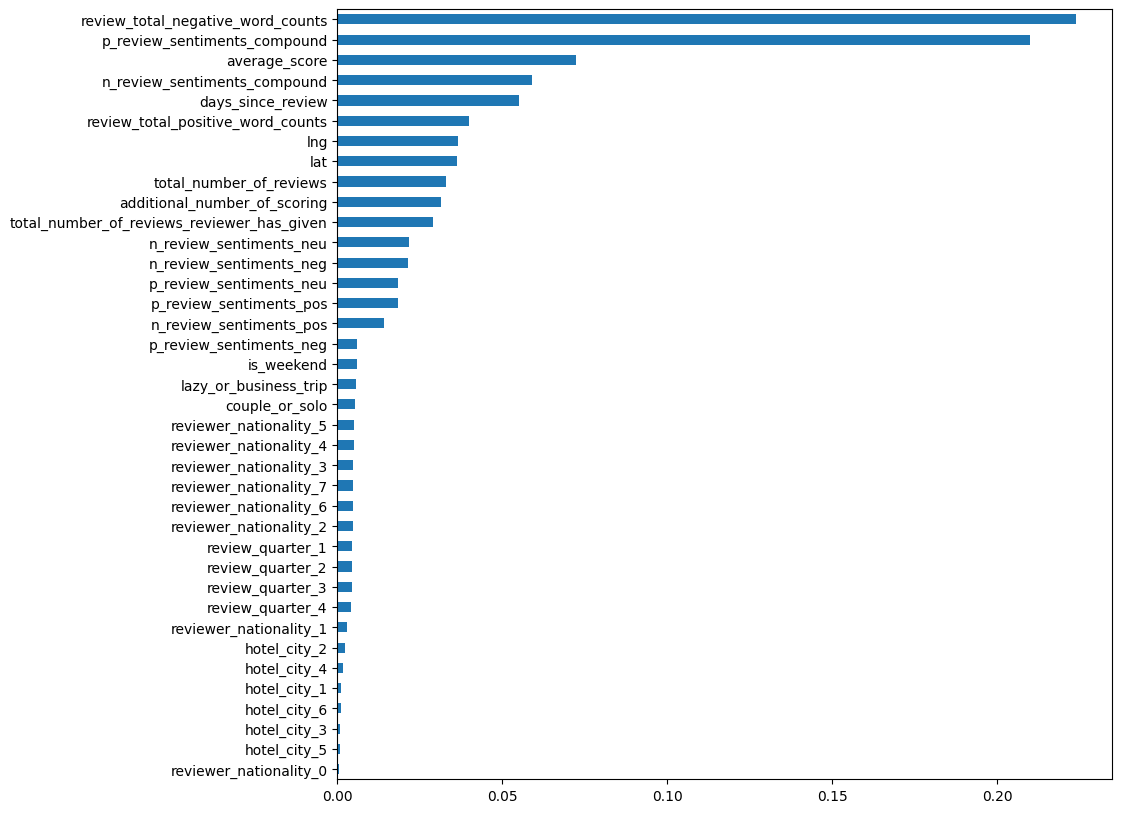

In [51]:
# в RandomForestRegressor есть возможность вывести самые важные признаки для модели
plt.rcParams['figure.figsize'] = (10,10)
feat_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
feat_importances.nlargest(38).sort_values(ascending=True).plot(kind='barh')

Выводы по важности признаков:
В целом важность признаков, полученная при помощи статистических тестов и в результате построения предсказательной модели модели совпадают.
Также, можно обратить внимание, что числовые признаки оказываю намного большее влияние на целевую переменную, чем категориальные.

In [52]:
# Делаем предсказание для соревнования
test_data_X = test_data.drop(['reviewer_score'], axis=1)

In [53]:
predict_submission = model.predict(test_data_X)

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    1.1s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:    2.8s finished


In [54]:
sample_submission.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128935 entries, 0 to 128934
Data columns (total 2 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   reviewer_score  128935 non-null  int64
 1   id              128935 non-null  int64
dtypes: int64(2)
memory usage: 2.0 MB


In [55]:
sample_submission['reviewer_score'] = predict_submission
# создаем субмишшен файл
sample_submission.to_csv('submission2.csv', index=False)
sample_submission.head(5)

,reviewer_score,id
0,8.591,488440
1,7.331,274649
2,8.493,374688
3,9.787,404352
4,9.542,451596


Отправленный на платформу Kaggle субмишен показал результат 12.61923 (аккаунт ds_hollywood)

### 6. Общие выводы:
1. В результате данной работы мы:
- произвели первичный анализ датасета
- заполнили пропуски в данных
- произвели генерацию новых признаков
- закодировали категориальные признаки
- провели статистические тесты для оценки важности признаков (с тепень их влияния на целевой признак) и отобразили результаты на графике
- построили тепловые таблицы корреляции признаков для оценки мультиколлинеарности
- провели отбор признаков (хотя по факту решено оставить все признаки)
- построили предсказательную модель RandomForestRegressor
- оценили результаты предсказания модели
- создали и отправили submission файл на платформу Kaggle, получили приемлимый результат